In [1]:
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np
from itertools import cycle, product
from pathlib import Path

%cd /g/data/w42/dr6273/work/wind_drought/
import src.wind as wind
import src.utils as utils

/g/data/w42/dr6273/work/wind_drought


In [2]:
%load_ext autoreload
%autoreload 2

### Wind data

In [3]:
def load_wind(dataset, variable, region, scenario=None, averaging="equal"):
    """ Return da of wind speed data for given criteria """
    wind_path = "/g/data/ng72/dr6273/work/projects/wind_drought/data/"+dataset+"/power_grid/"
    directory_path = Path(wind_path)

    # Filter by variable
    matching_files = [f.name for f in directory_path.iterdir() if f.is_file() and variable in f.name]

    # Filter by region
    matching_files = [f for f in matching_files if region in f]

    # Filter by scenario
    if scenario is not None:
        matching_files = [f for f in matching_files if scenario in f]

    # Filter by averaging method
    matching_files = [f for f in matching_files if averaging in f]
    
    if len(matching_files) > 1:
        raise ValueError("Need to filter more files")
        
    return xr.open_dataset(wind_path + matching_files[0])

In [4]:
# REGIONS = ["NEM-SC30", "SE-SC30", "SWIS", "NWIS"]

In [5]:
obs_dict = {}
for dataset in ["ERA5", "BARRA-R2"]:
    obs_dict[dataset] = {}

    for variable in ["wind_speed", "capacity_factor"]:
        obs_dict[dataset][variable] = {}

        for region in ["NEM", "SE", "SWIS", "NWIS"]:
            
            if region in ["NEM", "SE"]:
                for scenario in ["SC30", "SC40", "SC50"]:
                    obs_dict[dataset][variable][region+"-"+scenario] = {}

                    for averaging in ["equal", "weighted"]:
                        da = load_wind(dataset, variable, region, scenario, averaging)
                        obs_dict[dataset][variable][region+"-"+scenario][averaging] = da[variable]

            else:
                da = load_wind(dataset, variable, region)
                obs_dict[dataset][variable][region] = da[variable]

#### Seasonal cycle

In [6]:
def plot_seasonal_cycle(
    ax, da_dict, dataset, region, scenario, averaging, variable, reducer="mean"
):
    """Plot seasonal cycles by mean or quantile."""

    def as_list(value):
        return value if isinstance(value, (list, tuple)) else [value]

    datasets = as_list(dataset)
    regions = as_list(region)
    scenarios = as_list(scenario)
    averages = as_list(averaging)

    markers = cycle(["o", None, "s", "^"])
    marker_by_dataset = dict(zip(datasets, markers))

    colors = ["#648FFF", "#DC267F", "#FFB000"]

    def reduce_monthly(da):
        if reducer == "mean":
            return da.groupby("time.month").mean()
        if isinstance(reducer, float) and 0.0 <= reducer <= 1.0:
            return da.groupby("time.month").quantile(reducer, dim="time")
        raise ValueError("reducer must be 'mean' or a float between 0 and 1")

    if all(r in ["NEM", "SE"] for r in regions):
        combinations = list(product(regions, scenarios))
        color_for = dict(zip(combinations, colors))

        for ds, reg, scen, avg in product(datasets, regions, scenarios, averages):
            da = da_dict[ds][variable][f"{reg}-{scen}"][avg]
            da_reduced = reduce_monthly(da)
            label = f"{ds}, {reg}-{scen}, {avg}"

            da_reduced.plot(
                ax=ax,
                marker=marker_by_dataset[ds],
                ls="-" if avg == averages[0] else "--",
                label=label,
                color=color_for[(reg, scen)],
            )
    else:
        color_for = dict(zip(regions, colors))

        for ds, reg in product(datasets, regions):
            da = da_dict[ds][variable][reg]
            da_reduced = reduce_monthly(da)

            da_reduced.plot(
                ax=ax,
                marker=marker_by_dataset[ds],
                ls="-",
                label=f"{ds}, {reg}",
                color=color_for[reg],
            )

    ax.legend(ncol=2, fontsize=8)

    if variable == "capacity_factor":
        ax.set_ylabel("Capacity factor [-]")

    reducer_name = (
        "mean" if reducer == "mean"
        else f"{int(reducer * 100)}th pctl"
    )
    ax.set_title(
        f"{', '.join(regions)} {reducer_name} {variable.replace('_', ' ')}",
        fontsize=10,
        loc="center",
    )

In [7]:
SCENARIOS = ["SC30", "SC40", "SC50"]
AVERAGINGS = ["equal", "weighted"]

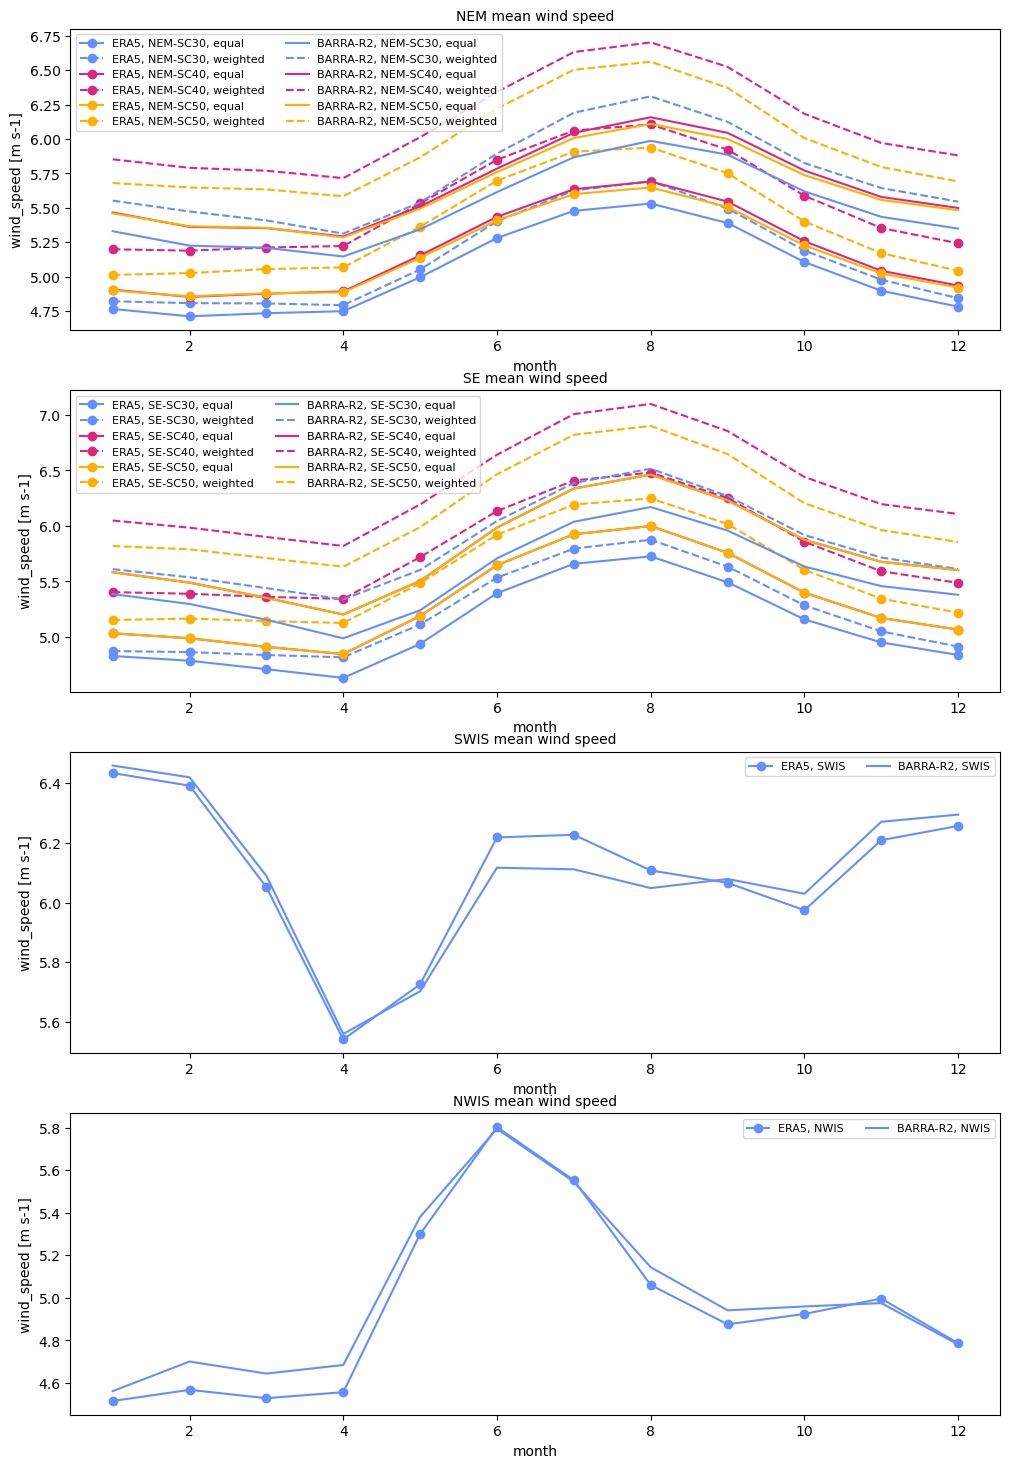

In [13]:
fig, ax = plt.subplots(4, 1, figsize=(12,18))

for i, (r, s, a) in enumerate(zip(
    ["NEM", "SE", "SWIS", "NWIS"], [SCENARIOS, SCENARIOS, None, None], [AVERAGINGS, AVERAGINGS, None, None]
)):
    plot_seasonal_cycle(
        ax[i], obs_dict,
        dataset=["ERA5", "BARRA-R2"],
        region=r,
        scenario=s,
        averaging=a,
        variable="wind_speed",
    )
plt.savefig("figures/seasonal_cycle_mean_wind_speed.png", dpi=300)

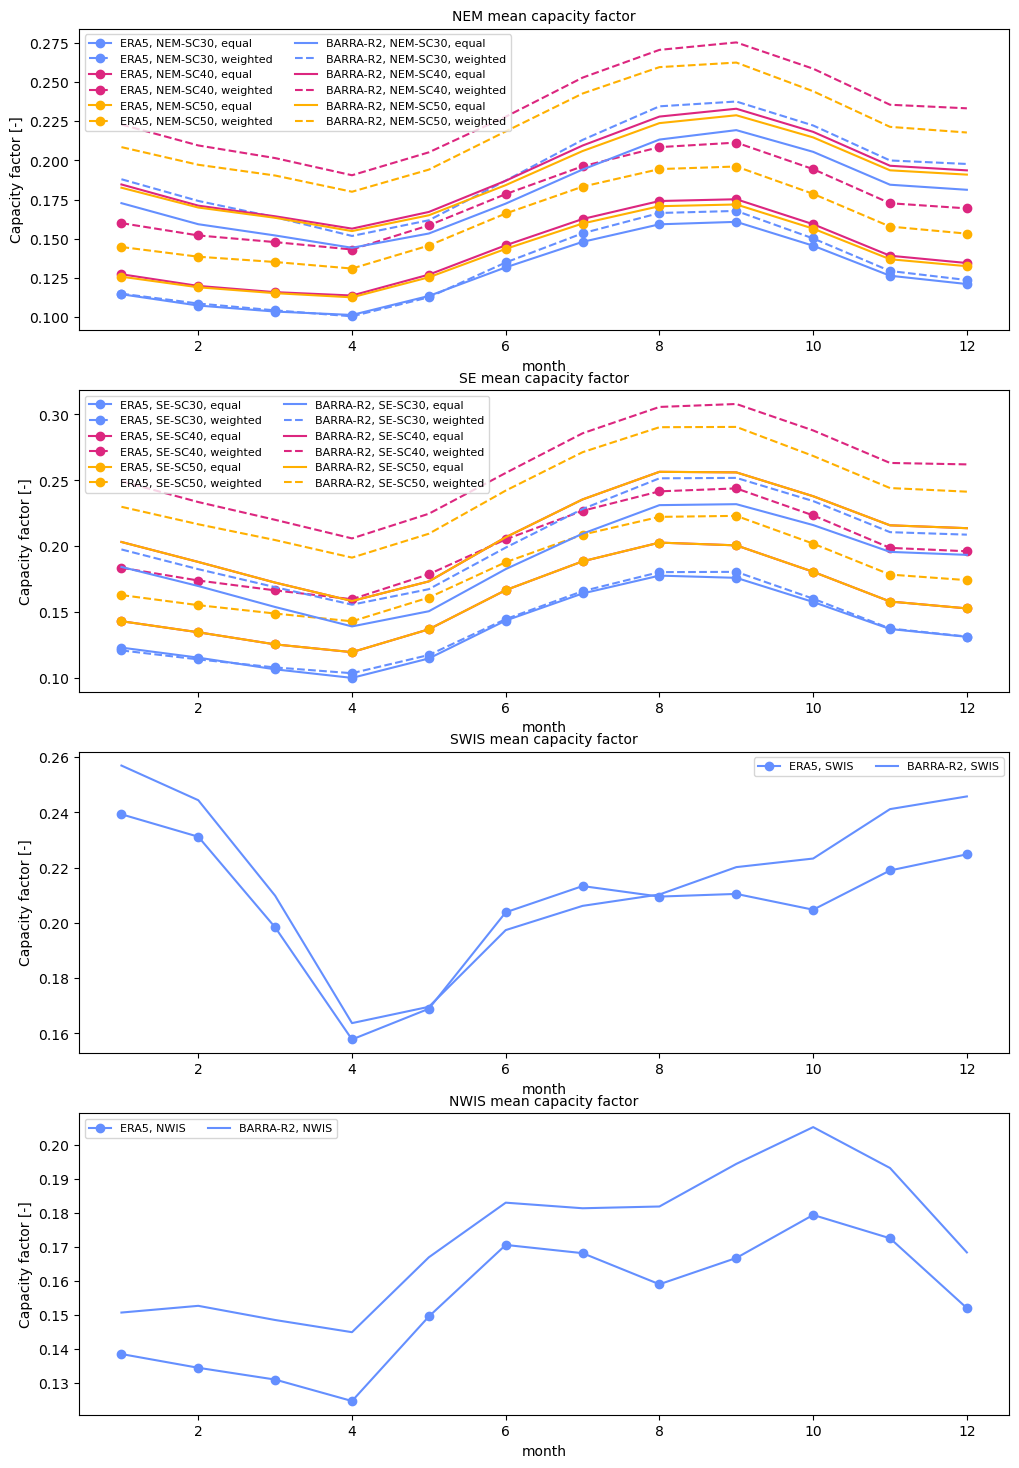

In [14]:
fig, ax = plt.subplots(4, 1, figsize=(12,18))

for i, (r, s, a) in enumerate(zip(
    ["NEM", "SE", "SWIS", "NWIS"], [SCENARIOS, SCENARIOS, None, None], [AVERAGINGS, AVERAGINGS, None, None]
)):
    plot_seasonal_cycle(
        ax[i], obs_dict,
        dataset=["ERA5", "BARRA-R2"],
        region=r,
        scenario=s,
        averaging=a,
        variable="capacity_factor",
    )
plt.savefig("figures/seasonal_cycle_mean_capacity_factor.png", dpi=300)

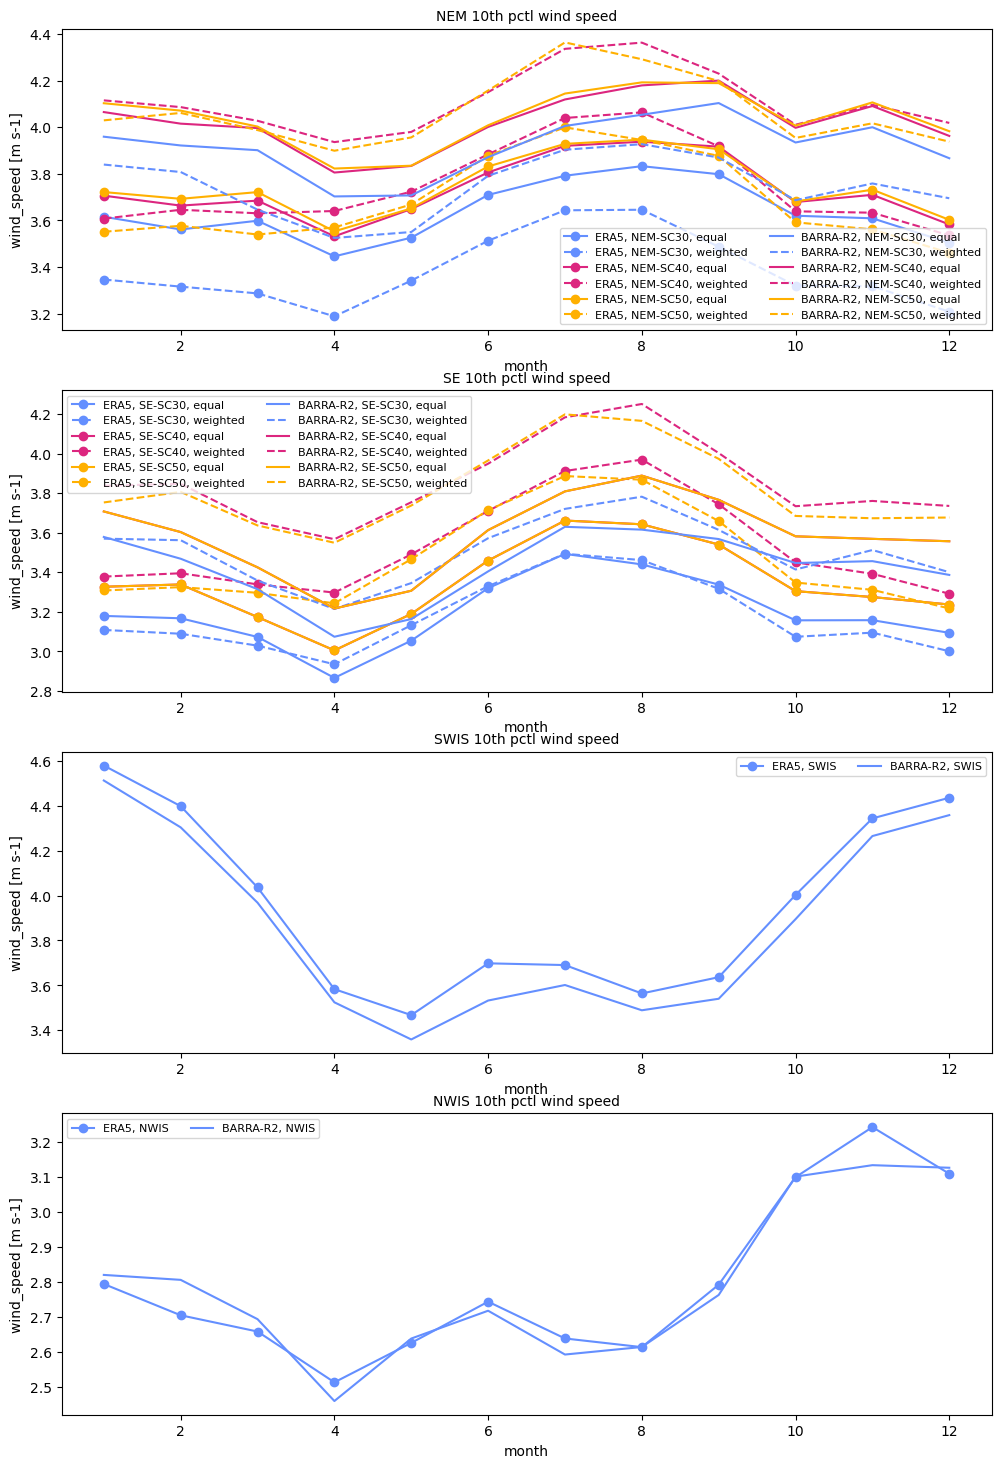

In [15]:
fig, ax = plt.subplots(4, 1, figsize=(12,18))

for i, (r, s, a) in enumerate(zip(
    ["NEM", "SE", "SWIS", "NWIS"], [SCENARIOS, SCENARIOS, None, None], [AVERAGINGS, AVERAGINGS, None, None]
)):
    plot_seasonal_cycle(
        ax[i], obs_dict,
        dataset=["ERA5", "BARRA-R2"],
        region=r,
        scenario=s,
        averaging=a,
        variable="wind_speed",
        reducer=0.1
    )
plt.savefig("figures/seasonal_cycle_10pctl_wind_speed.png", dpi=300)

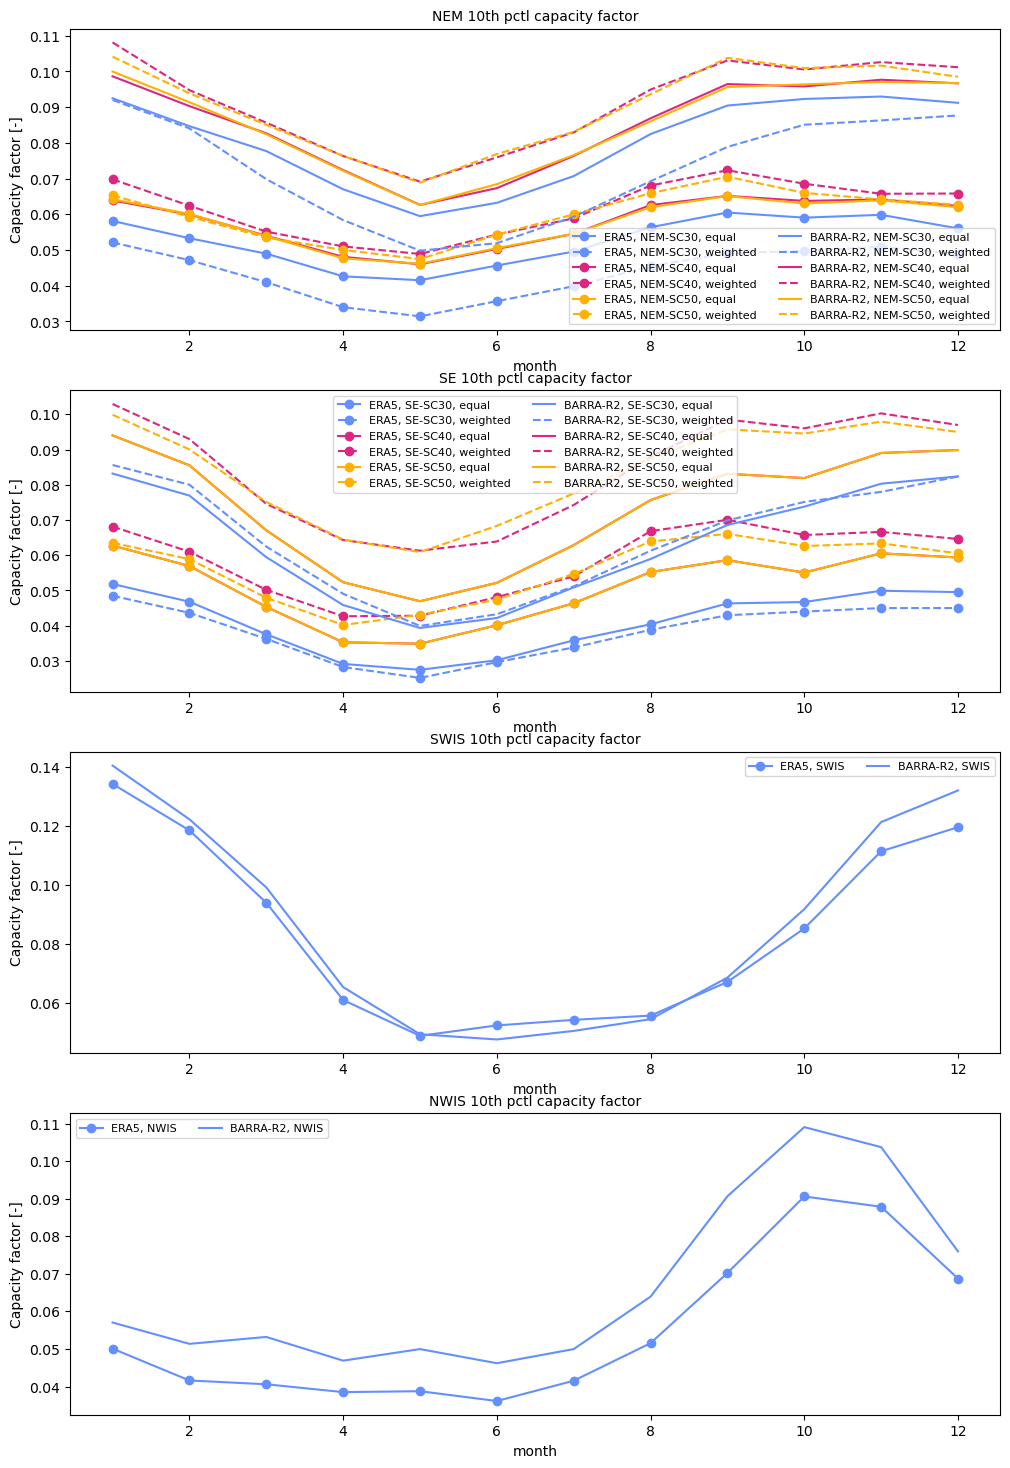

In [16]:
fig, ax = plt.subplots(4, 1, figsize=(12,18))

for i, (r, s, a) in enumerate(zip(
    ["NEM", "SE", "SWIS", "NWIS"], [SCENARIOS, SCENARIOS, None, None], [AVERAGINGS, AVERAGINGS, None, None]
)):
    plot_seasonal_cycle(
        ax[i], obs_dict,
        dataset=["ERA5", "BARRA-R2"],
        region=r,
        scenario=s,
        averaging=a,
        variable="capacity_factor",
        reducer=0.1
    )
plt.savefig("figures/seasonal_cycle_10pctl_capacity_factor.png", dpi=300)

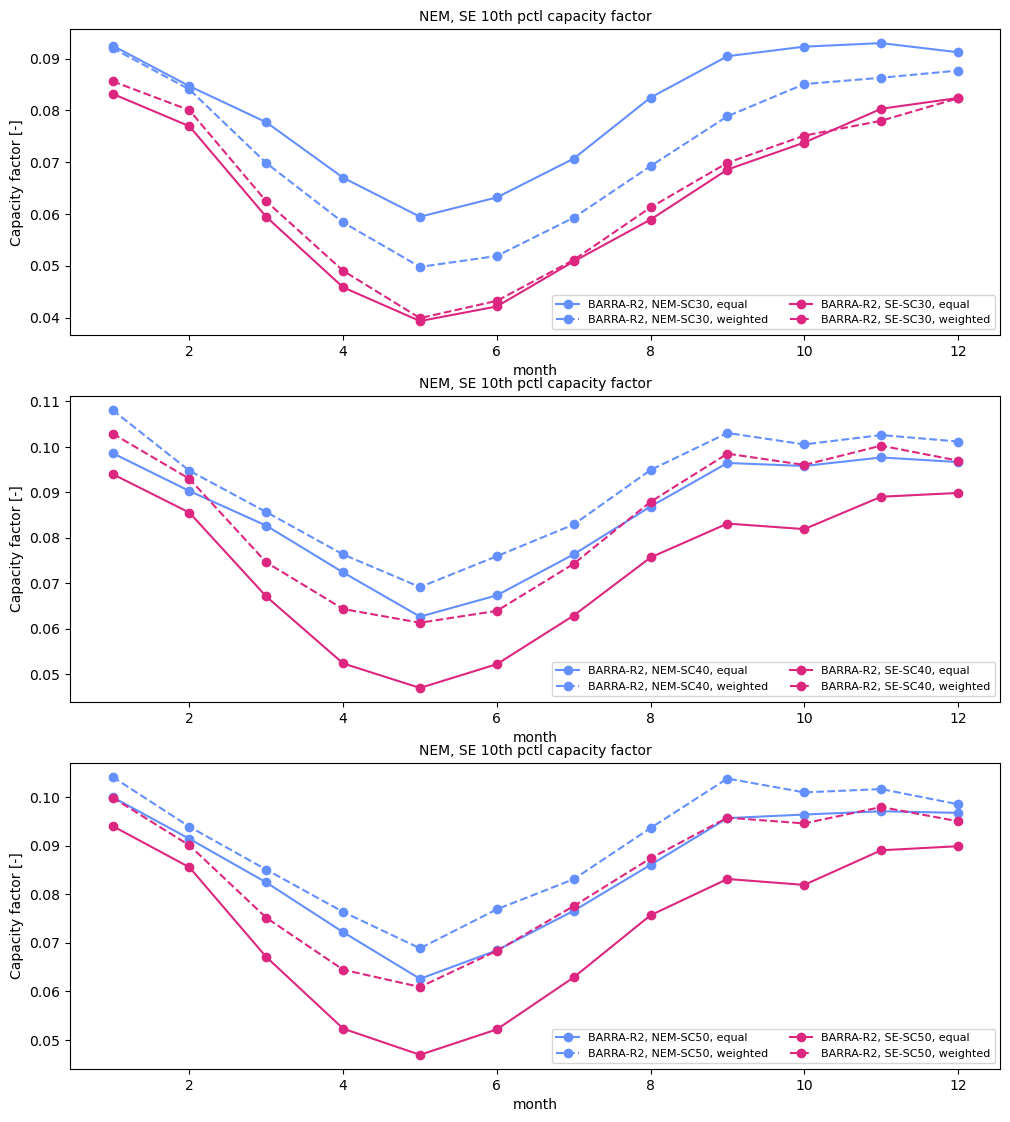

In [19]:
fig, ax = plt.subplots(3, 1, figsize=(12,13.5))

regions = ["NEM", "SE"]

for i, (r, s, a) in enumerate(zip(
    [regions, regions, regions], [SCENARIOS[0], SCENARIOS[1], SCENARIOS[2]], [AVERAGINGS, AVERAGINGS, AVERAGINGS]
)):
    plot_seasonal_cycle(
        ax[i], obs_dict,
        dataset=["BARRA-R2"],
        region=r,
        scenario=s,
        averaging=a,
        variable="capacity_factor",
        reducer=0.1
    )
# plt.savefig("figures/seasonal_cycle_10pctl_capacity_factor.png", dpi=300)


#### Wind statistics

In [8]:
def plot_ws_hist(ax, da, title, label=None):
    """ Histogram of wind speed """
    bins = np.arange(0, 18.5, 1)
    ax.hist(da, bins=bins, density=True, rwidth=0.9, label=label, color='tab:blue', alpha=0.5)
    
    pctl10 = np.percentile(da, 10)
    print(pctl10)
    print(da.max().values)
    print()
    ax.axvline(pctl10, color='tab:blue', label='10th percentile')
    
    ax.set_xlabel('daily average surface wind speed [m/s]')
    ax.set_ylabel('Probability density [s/m]')
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, 18)
    ax.set_ylim(0, 0.3)
    ax.legend()

3.7401483310020396
15.061850432238957

3.4918268419780083
16.497542103707175

3.7941960623671878
15.162852373201968

2.7614675300953904
17.942070404575745



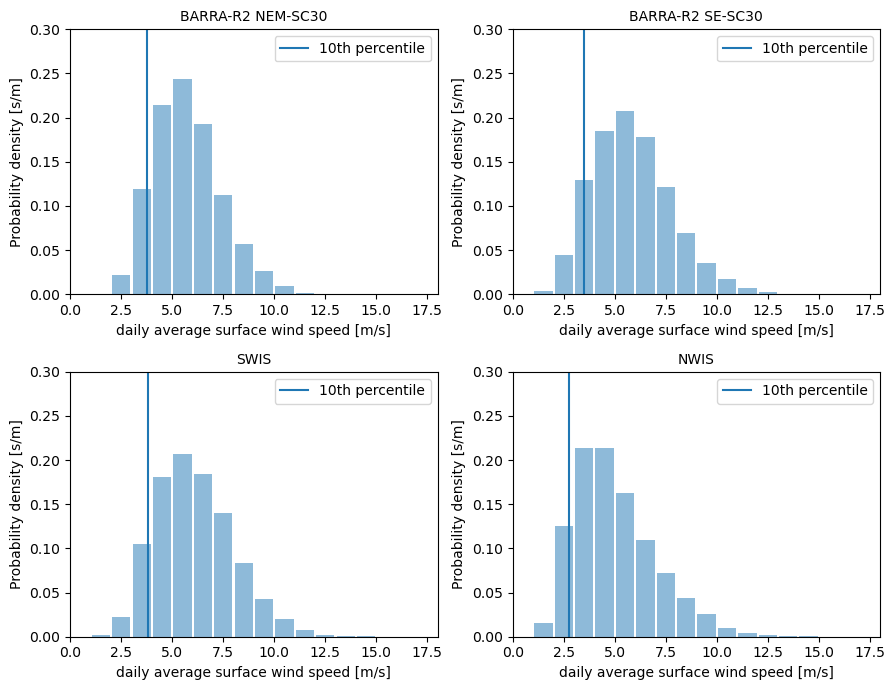

In [53]:
_to_plot =[
    obs_dict["BARRA-R2"]['wind_speed']['NEM-SC30']['weighted'],
    obs_dict["BARRA-R2"]['wind_speed']['SE-SC30']['weighted'],
    obs_dict["BARRA-R2"]['wind_speed']['SWIS'],
    obs_dict["BARRA-R2"]['wind_speed']['NWIS']
]

fig, axes = plt.subplots(2, 2, figsize=(9,7))
for i, (title, da) in enumerate(zip(
    ["BARRA-R2 NEM-SC30", "BARRA-R2 SE-SC30", "SWIS", "NWIS"], _to_plot
)):
    ax = axes.flatten()[i]
    plot_ws_hist(ax, da, title)
plt.tight_layout()

3.7439187955218367
12.320416013458546

3.532813069287953
14.024577223791656

3.480204109386182
15.162852373201968

2.6451838727239707
12.433447655263826



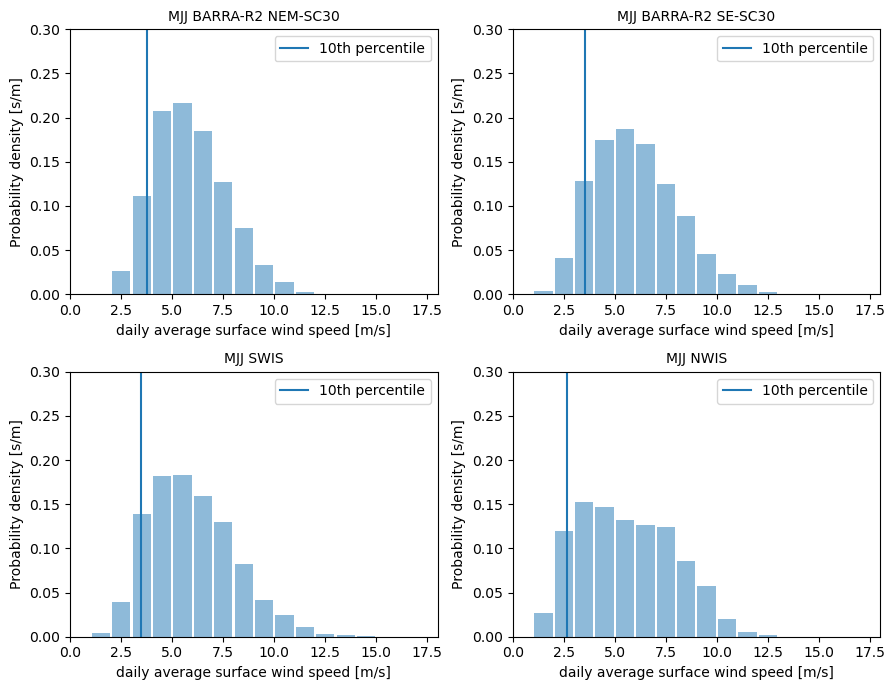

In [60]:
_to_plot =[
    utils.sel_month(obs_dict["BARRA-R2"]['wind_speed']['NEM-SC30']['weighted'], [5, 6, 7]),
    utils.sel_month(obs_dict["BARRA-R2"]['wind_speed']['SE-SC30']['weighted'], [5, 6, 7]),
    utils.sel_month(obs_dict["BARRA-R2"]['wind_speed']['SWIS'], [5, 6, 7]),
    utils.sel_month(obs_dict["BARRA-R2"]['wind_speed']['NWIS'], [5, 6, 7]),
]

fig, axes = plt.subplots(2, 2, figsize=(9,7))
for i, (title, da) in enumerate(zip(
    ["BARRA-R2 NEM-SC30", "BARRA-R2 SE-SC30", "SWIS", "NWIS"], _to_plot
)):
    ax = axes.flatten()[i]
    plot_ws_hist(ax, da, "MJJ " + title)
plt.tight_layout()

In [84]:
def plot_cf_hist(ax, da, title, label=None):
    """ Histogram of capacity factors """
    bins = np.arange(0, 1.05, 0.05)
    ax.hist(da, bins=bins, density=True, rwidth=0.9, label=label, color='tab:blue', alpha=0.5)
    
    pctl10 = np.percentile(da, 10)
    print(pctl10)
    print(da.max().values)
    print()
    ax.axvline(pctl10, color='tab:blue', label='10th percentile')
    
    ax.set_xlabel('daily average capacity factor [-]')
    ax.set_ylabel('Probability density [-]')
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 6)
    ax.legend()

0.07031893644434703
0.8771798379771554

0.06255955304302793
0.9756511667695624

0.07183690291207297
0.9591506510509272

0.05951697960918796
0.99369991037247



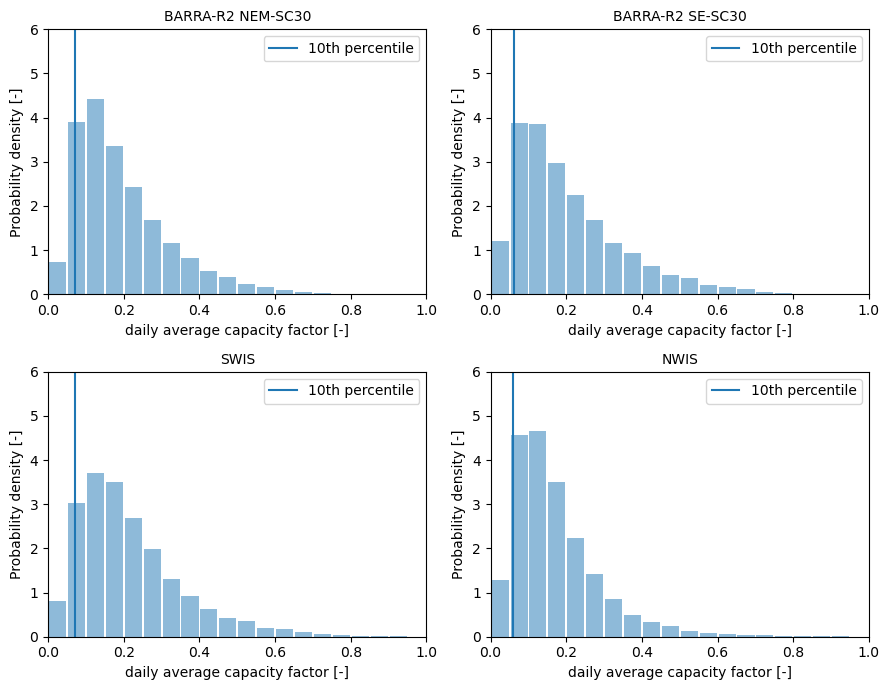

In [86]:
_to_plot =[
    obs_dict["BARRA-R2"]['capacity_factor']['NEM-SC30']['weighted'],
    obs_dict["BARRA-R2"]['capacity_factor']['SE-SC30']['weighted'],
    obs_dict["BARRA-R2"]['capacity_factor']['SWIS'],
    obs_dict["BARRA-R2"]['capacity_factor']['NWIS']
]

fig, axes = plt.subplots(2, 2, figsize=(9,7))
for i, (title, da) in enumerate(zip(
    ["BARRA-R2 NEM-SC30", "BARRA-R2 SE-SC30", "SWIS", "NWIS"], _to_plot
)):
    ax = axes.flatten()[i]
    plot_cf_hist(ax, da, title)
plt.tight_layout()

0.05377378700000129
0.7639863055970927

0.044396143240629
0.8807837285464754

0.04917439000126201
0.9591506510509272

0.048613339175840306
0.8124591110184364



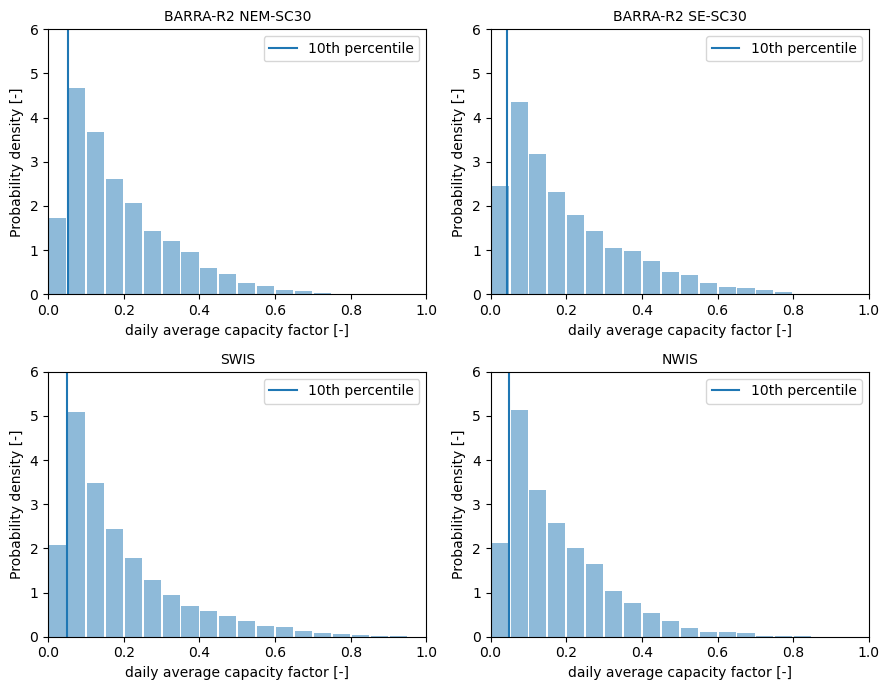

In [85]:
_to_plot =[
    utils.sel_month(obs_dict["BARRA-R2"]['capacity_factor']['NEM-SC30']['weighted'], [5, 6, 7]),
    utils.sel_month(obs_dict["BARRA-R2"]['capacity_factor']['SE-SC30']['weighted'], [5, 6, 7]),
    utils.sel_month(obs_dict["BARRA-R2"]['capacity_factor']['SWIS'], [5, 6, 7]),
    utils.sel_month(obs_dict["BARRA-R2"]['capacity_factor']['NWIS'], [5, 6, 7]),
]

fig, axes = plt.subplots(2, 2, figsize=(9,7))
for i, (title, da) in enumerate(zip(
    ["BARRA-R2 NEM-SC30", "BARRA-R2 SE-SC30", "SWIS", "NWIS"], _to_plot
)):
    ax = axes.flatten()[i]
    plot_cf_hist(ax, da, title)
plt.tight_layout()

### Wind drought durations (WDD)

- Define a drought day as below the MJJ 10th percentile.
- 10th percentile MJJ vs whole year is similar for wind speed, and slightly lower for capacity factors (0.5 vs 0.7 for NEM)

In [9]:
def map_leaves(obj, operation):
    if isinstance(obj, dict):
        return {key: map_leaves(value, operation) for key, value in obj.items()}
    return operation(obj)

In [17]:
def plot_wdd_hist(ax, da, title, labels=None):
    """Histogram of WDD; accepts one array or a list of two arrays."""
    bins = np.arange(0, 10.1, 1)

    arrays = da if isinstance(da, (list, tuple)) else [da]
    labels = labels if isinstance(labels, (list, tuple)) else [labels]
    colors = ["tab:blue", "tab:orange"]

    for arr, color, label in zip(arrays, colors, labels):
        ax.hist(
            arr, bins=bins, density=True, rwidth=0.9,
            label=label, color=color, alpha=0.5
        )
        print(arr.max().values)
        print()

    if labels is not None:
        ax.legend()
    ax.set_xlabel("WDD [d]")
    ax.set_ylabel("Probability density [1/d]")
    ax.set_title(title, fontsize=10)
    ax.set_xlim(1, 10)
    ax.set_xticks(np.arange(1.5, 10, 1))
    ax.set_xticklabels(range(1, 10))
    ax.set_yscale("log")

In [10]:
wdd_dict = map_leaves(
    obs_dict,
    lambda value: wind.calc_wdd_timeseries(
        value, utils.sel_month(value, [5, 6, 7]).quantile(0.1, "time")
    )
)

8.0

8.0

6.0

7.0

5.0

6.0



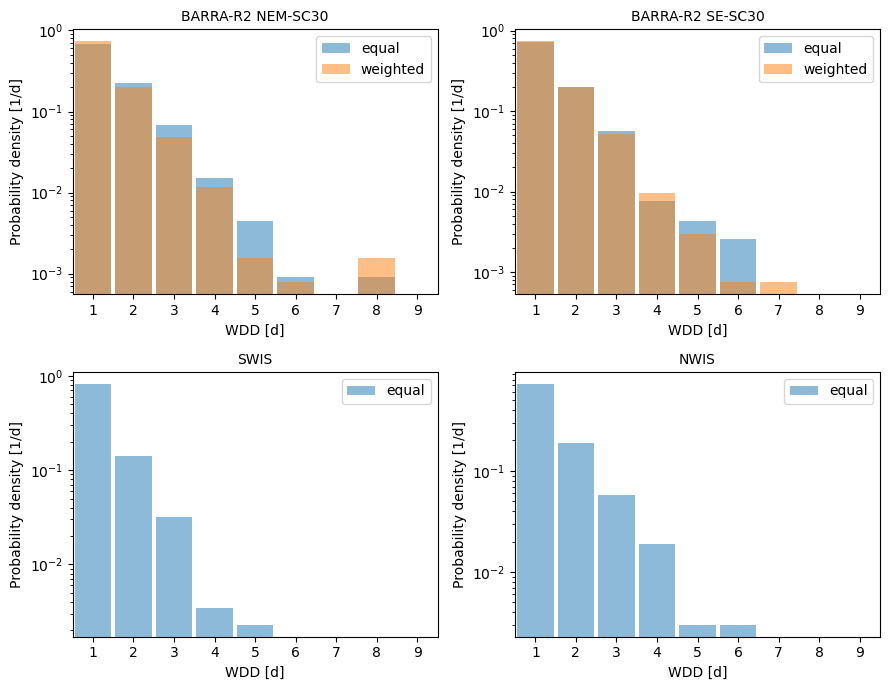

In [19]:
_to_plot =[
    [
        wdd_dict["BARRA-R2"]['wind_speed']['NEM-SC30']['equal'],
        wdd_dict["BARRA-R2"]['wind_speed']['NEM-SC30']['weighted']
    ],
    [
        wdd_dict["BARRA-R2"]['wind_speed']['SE-SC30']['equal'],
        wdd_dict["BARRA-R2"]['wind_speed']['SE-SC30']['weighted']
    ],
    wdd_dict["BARRA-R2"]['wind_speed']['SWIS'],
    wdd_dict["BARRA-R2"]['wind_speed']['NWIS']
]

fig, axes = plt.subplots(2, 2, figsize=(9,7))
for i, (title, da) in enumerate(zip(
    ["BARRA-R2 NEM-SC30", "BARRA-R2 SE-SC30", "SWIS", "NWIS"], _to_plot
)):
    ax = axes.flatten()[i]
    plot_wdd_hist(ax, da, title, ["equal", "weighted"])
plt.tight_layout()

8.0

9.0

8.0

8.0

5.0

7.0



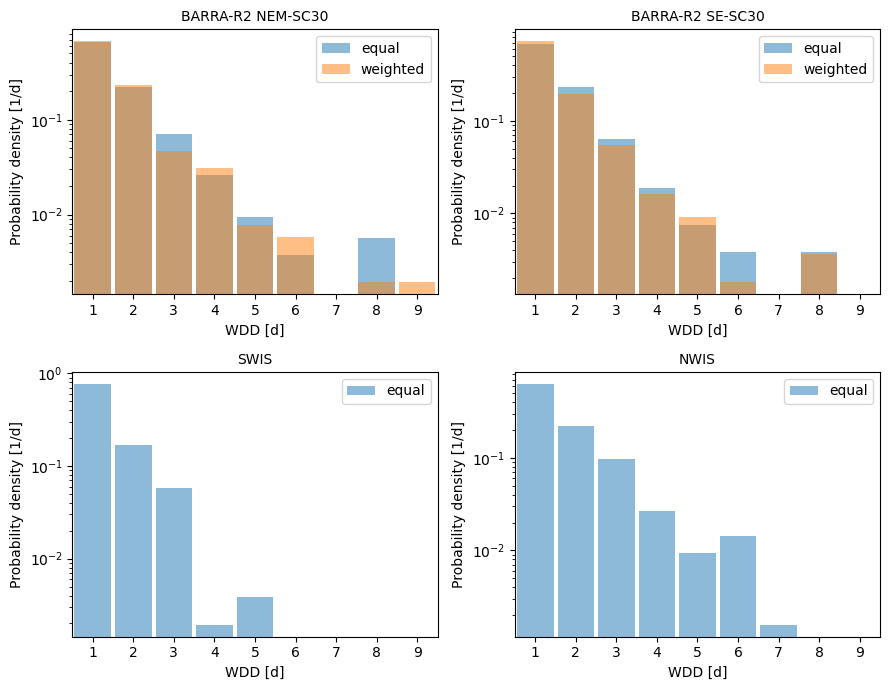

In [21]:
_to_plot =[
    [
        wdd_dict["BARRA-R2"]['capacity_factor']['NEM-SC30']['equal'],
        wdd_dict["BARRA-R2"]['capacity_factor']['NEM-SC30']['weighted']
    ],
    [
        wdd_dict["BARRA-R2"]['capacity_factor']['SE-SC30']['equal'],
        wdd_dict["BARRA-R2"]['capacity_factor']['SE-SC30']['weighted']
    ],
    wdd_dict["BARRA-R2"]['capacity_factor']['SWIS'],
    wdd_dict["BARRA-R2"]['capacity_factor']['NWIS']
]

fig, axes = plt.subplots(2, 2, figsize=(9,7))
for i, (title, da) in enumerate(zip(
    ["BARRA-R2 NEM-SC30", "BARRA-R2 SE-SC30", "SWIS", "NWIS"], _to_plot
)):
    ax = axes.flatten()[i]
    plot_wdd_hist(ax, da, title, ["equal", "weighted"])
plt.tight_layout()

9.0

9.0

8.0

9.0

5.0

6.0

7.0

9.0



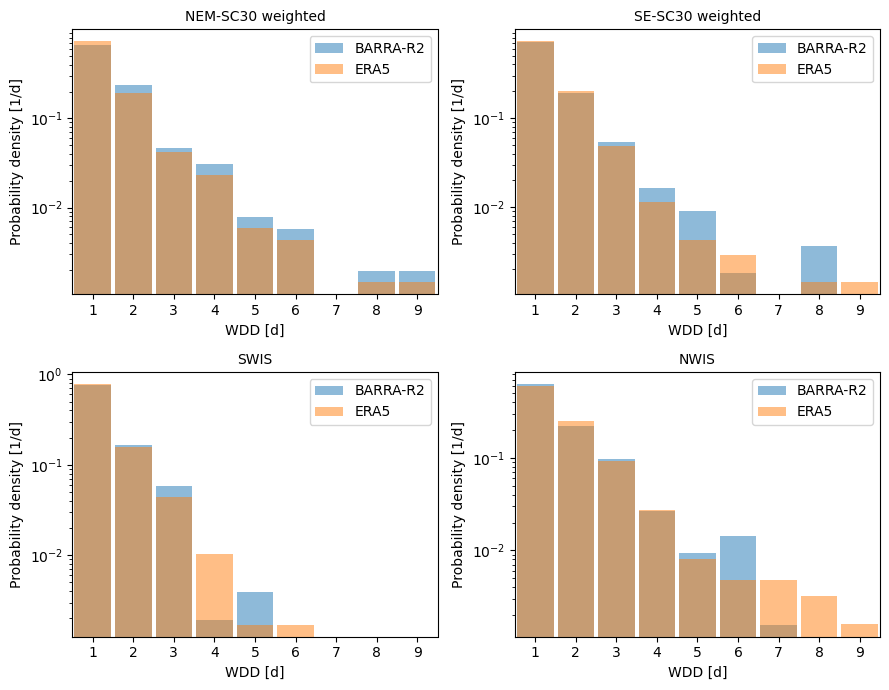

In [33]:
_to_plot =[
    [
        wdd_dict["BARRA-R2"]['capacity_factor']['NEM-SC30']['weighted'],
        wdd_dict["ERA5"]['capacity_factor']['NEM-SC30']['weighted']
    ],
    [
        wdd_dict["BARRA-R2"]['capacity_factor']['SE-SC30']['weighted'],
        wdd_dict["ERA5"]['capacity_factor']['SE-SC30']['weighted']
    ],
    [
        wdd_dict["BARRA-R2"]['capacity_factor']['SWIS'],
        wdd_dict["ERA5"]['capacity_factor']['SWIS']
    ],
    [
        wdd_dict["BARRA-R2"]['capacity_factor']['NWIS'],
        wdd_dict["ERA5"]['capacity_factor']['NWIS']
    ]
]

fig, axes = plt.subplots(2, 2, figsize=(9,7))
for i, (title, da) in enumerate(zip(
    ["NEM-SC30 weighted", "SE-SC30 weighted", "SWIS", "NWIS"], _to_plot
)):
    ax = axes.flatten()[i]
    plot_wdd_hist(ax, da, title, ["BARRA-R2", "ERA5"])
plt.tight_layout()

8.0

9.0

8.0

9.0

8.0

9.0



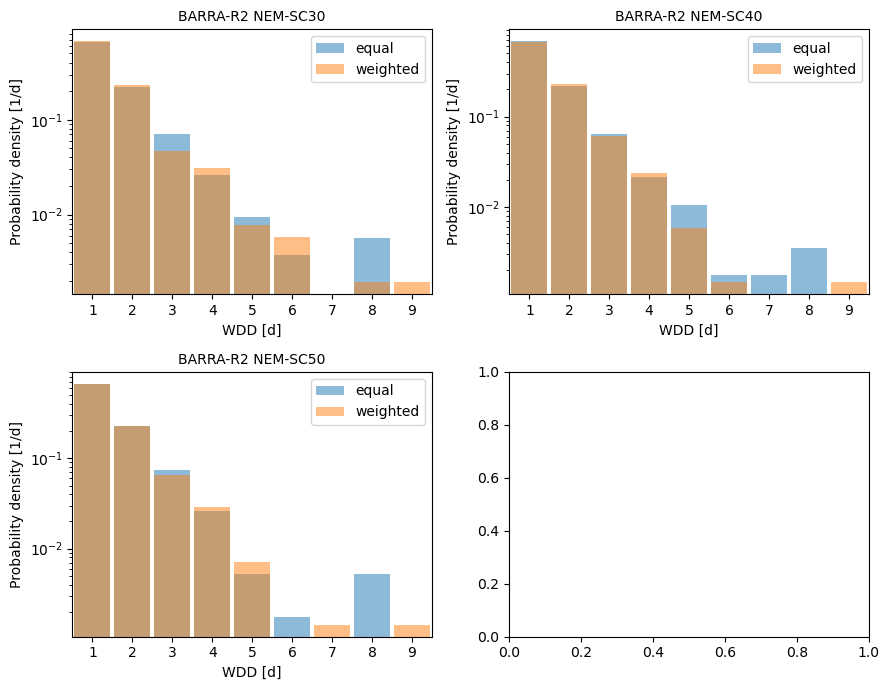

In [23]:
_to_plot =[
    [
        wdd_dict["BARRA-R2"]['capacity_factor']['NEM-SC30']['equal'],
        wdd_dict["BARRA-R2"]['capacity_factor']['NEM-SC30']['weighted']
    ],
    [
        wdd_dict["BARRA-R2"]['capacity_factor']['NEM-SC40']['equal'],
        wdd_dict["BARRA-R2"]['capacity_factor']['NEM-SC40']['weighted']
    ],
    [
        wdd_dict["BARRA-R2"]['capacity_factor']['NEM-SC50']['equal'],
        wdd_dict["BARRA-R2"]['capacity_factor']['NEM-SC50']['weighted']
    ],
    # [
    #     wdd_dict["BARRA-R2"]['capacity_factor']['SE-SC40']['equal'],
    #     wdd_dict["BARRA-R2"]['capacity_factor']['SE-SC40']['weighted']
    # ],
]

fig, axes = plt.subplots(2, 2, figsize=(9,7))
for i, (title, da) in enumerate(zip(
    ["BARRA-R2 NEM-SC30", "BARRA-R2 NEM-SC40", "BARRA-R2 NEM-SC50"], _to_plot
)):
    ax = axes.flatten()[i]
    plot_wdd_hist(ax, da, title, ["equal", "weighted"])
plt.tight_layout()

#### Annual maximum wind drought duration (WDDx)

In [26]:
wddx_dict = map_leaves(
    obs_dict,
    lambda value: wind.calc_wddx_timeseries(
        value, utils.sel_month(value, [5, 6, 7]).quantile(0.1, "time")
    )["event_length"]
)

In [29]:
def plot_wddx_hist(ax, da, title, labels=None):
    """ Histogram of WDDx """
    bins = np.arange(0, 10.1, 1)

    arrays = da if isinstance(da, (list, tuple)) else [da]
    labels = labels if isinstance(labels, (list, tuple)) else [labels]
    colors = ["tab:blue", "tab:orange"]
    
    for arr, color, label in zip(arrays, colors, labels):
        ax.hist(
            arr, bins=bins, density=True, rwidth=0.9,
            label=label, color=color, alpha=0.5
        )
        print(arr.max().values)
        print()

    if labels is not None:
        ax.legend()
    
    ax.set_xlabel('WDDx [d]')
    ax.set_ylabel('Event count [-]')
    ax.set_title(title, fontsize=10)
    ax.set_xlim(1, 10)
    ax.set_xticks(np.arange(1.5, 10, 1))
    ax.set_xticklabels(range(1, 10, 1))

8.0

8.0

6.0

7.0

5.0

6.0



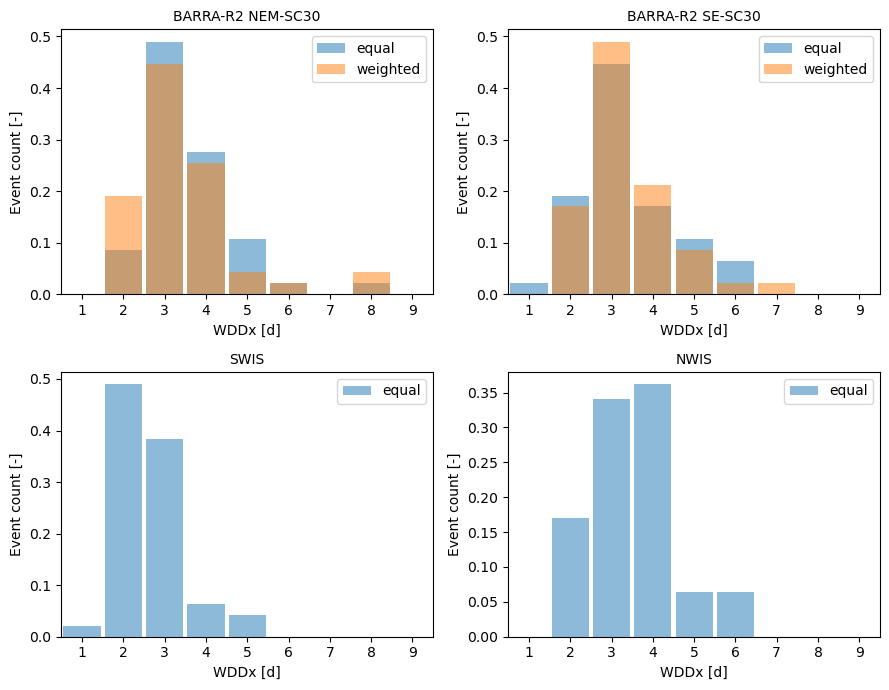

In [30]:
_to_plot =[
    [
        wddx_dict["BARRA-R2"]['wind_speed']['NEM-SC30']['equal'],
        wddx_dict["BARRA-R2"]['wind_speed']['NEM-SC30']['weighted']
    ],
    [
        wddx_dict["BARRA-R2"]['wind_speed']['SE-SC30']['equal'],
        wddx_dict["BARRA-R2"]['wind_speed']['SE-SC30']['weighted']
    ],
    wddx_dict["BARRA-R2"]['wind_speed']['SWIS'],
    wddx_dict["BARRA-R2"]['wind_speed']['NWIS']
]

fig, axes = plt.subplots(2, 2, figsize=(9,7))
for i, (title, da) in enumerate(zip(
    ["BARRA-R2 NEM-SC30", "BARRA-R2 SE-SC30", "SWIS", "NWIS"], _to_plot
)):
    ax = axes.flatten()[i]
    plot_wddx_hist(ax, da, title, ["equal", "weighted"])
plt.tight_layout()

8.0

9.0

8.0

8.0

5.0

7.0



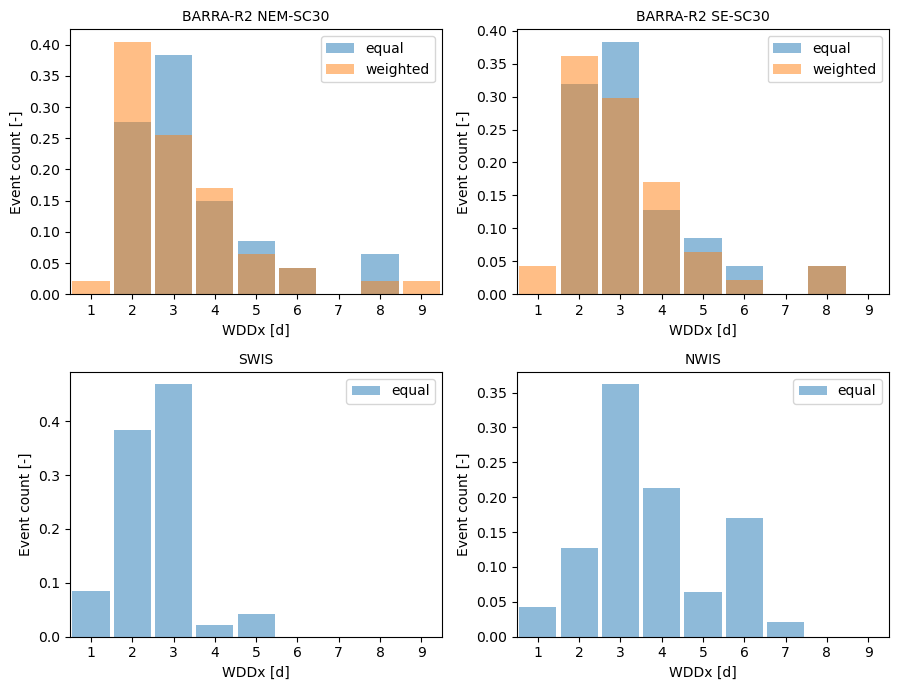

In [31]:
_to_plot =[
    [
        wddx_dict["BARRA-R2"]['capacity_factor']['NEM-SC30']['equal'],
        wddx_dict["BARRA-R2"]['capacity_factor']['NEM-SC30']['weighted']
    ],
    [
        wddx_dict["BARRA-R2"]['capacity_factor']['SE-SC30']['equal'],
        wddx_dict["BARRA-R2"]['capacity_factor']['SE-SC30']['weighted']
    ],
    wddx_dict["BARRA-R2"]['capacity_factor']['SWIS'],
    wddx_dict["BARRA-R2"]['capacity_factor']['NWIS']
]

fig, axes = plt.subplots(2, 2, figsize=(9,7))
for i, (title, da) in enumerate(zip(
    ["BARRA-R2 NEM-SC30", "BARRA-R2 SE-SC30", "SWIS", "NWIS"], _to_plot
)):
    ax = axes.flatten()[i]
    plot_wddx_hist(ax, da, title, labels=["equal", "weighted"])
plt.tight_layout()

9.0

9.0

8.0

9.0

5.0

6.0

7.0

9.0



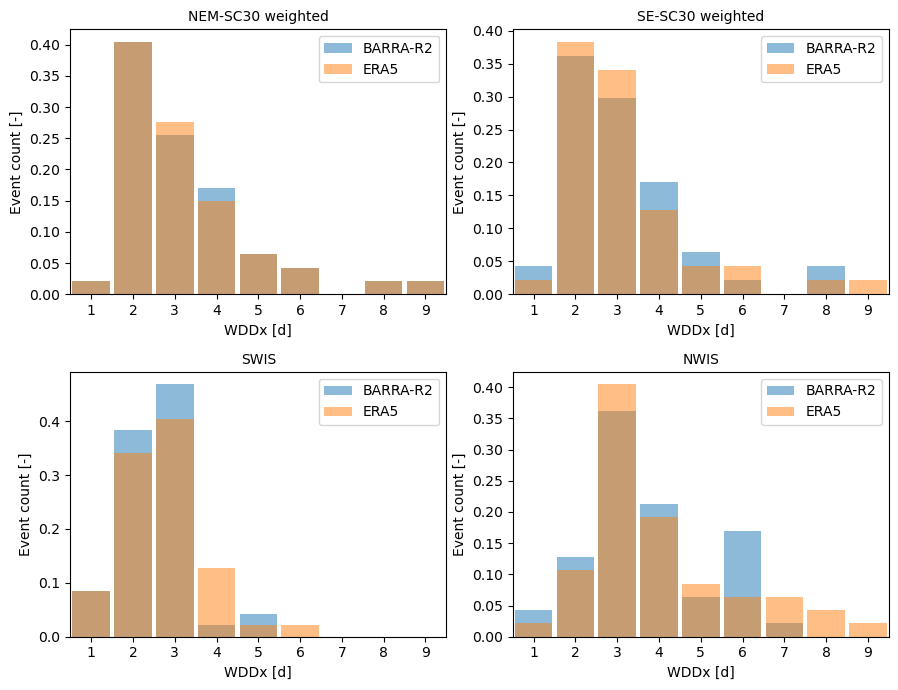

In [34]:
_to_plot =[
    [
        wddx_dict["BARRA-R2"]['capacity_factor']['NEM-SC30']['weighted'],
        wddx_dict["ERA5"]['capacity_factor']['NEM-SC30']['weighted']
    ],
    [
        wddx_dict["BARRA-R2"]['capacity_factor']['SE-SC30']['weighted'],
        wddx_dict["ERA5"]['capacity_factor']['SE-SC30']['weighted']
    ],
    [
        wddx_dict["BARRA-R2"]['capacity_factor']['SWIS'],
        wddx_dict["ERA5"]['capacity_factor']['SWIS']
    ],
    [
        wddx_dict["BARRA-R2"]['capacity_factor']['NWIS'],
        wddx_dict["ERA5"]['capacity_factor']['NWIS']
    ]
]

fig, axes = plt.subplots(2, 2, figsize=(9,7))
for i, (title, da) in enumerate(zip(
    ["NEM-SC30 weighted", "SE-SC30 weighted", "SWIS", "NWIS"], _to_plot
)):
    ax = axes.flatten()[i]
    plot_wddx_hist(ax, da, title, ["BARRA-R2", "ERA5"])
plt.tight_layout()